In [5]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [6]:
def find_box_corners(plon, plat, lon_edge, lat_edge):
    lat_min, lat_max = plat - lat_edge / 2, plat + lat_edge / 2
    lon_min, lon_max = plon - lon_edge / 2, plon + lon_edge / 2

    # Correct longitude boundaries
    while lon_min < -180:
        lon_min += 360
    while lon_max > 180:
        lon_max -= 360
    
    if lon_max % 1.5 == 0:
        lon_max -= 0.0001
    if lat_max % 1.5 == 0:
        lat_max -= 0.0001

    return lat_min, lat_max, lon_min, lon_max

In [7]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [8]:
def define_mask(lat_min,lat_max,
               lon_min,lon_max):
    
    lat_res, lon_res = 1.5, 1.5
    lats = np.arange(0, 91, lat_res)
    lons = np.arange(-180, 180, lon_res)
    
    mask = ((lats[:, None] >= lat_min) & (lats[:, None] <= lat_max) &
            (lons >= lon_min) & (lons <= lon_max))
    
    mask_xr = xr.DataArray(mask.astype(int), coords=[lats, lons], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1
    
    return mask_bool

In [9]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

box_edges=[[40,70,-180,180],
           [40,70,-180,180], 
           [40,70,75,160], 
           [40,70,75,160]]

ds_length = 730  # Number of days to consider for each dataset

# Load datasets
ds_clims = []
ds_composites = []
compute_climatology = False

if compute_climatology:
    for i,experiment in enumerate(experiments):
        print(experiment)

        #import needed fields
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc').isel(time=slice(0, ds_length))
        print('ds imported')
        LWAA_arr = ds['LWAA_tracked']
        print(LWAA_arr.shape)
        #in the second half of the dataset you need to change the sign of qgpv.
        time_length = LWAA_arr.shape[0]
        #qgpv_field = xr.concat([ds['dw_qgpv'][:int(time_length/2)], -ds['dw_qgpv'][int(time_length/2):]], dim='time')
        qgpv_field = ds['dw_qgpv']
        mean_qgpv_field = qgpv_field.mean('time')
        print(qgpv_field.shape)
        ds_temp = flip_and_append(xr.open_mfdataset(
            f'{base_path}/{experiment}/falwa_vars/atm_daily_uvt_*.nc',
            combine='by_coords',
            parallel=True,
            chunks={'time': 30}  # chunk size of one month (approximate)
        )).isel(time=slice(0, ds_length))
        t850 = ds_temp['temp'][:,3,:,:]
        mean_t850 = t850.mean('time')
        print(t850.shape)

        FC = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-11.nc')['FC']

        #import the tracking dictionary
        dic = np.load(f'{base_path}/{experiment}/tot/dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC.npy',allow_pickle=True)
        
        #compute blocking climatology

        block_freq = ds['LWAA_freq'].rename('block_freq')
        block_freq_std = (LWAA_arr.std('time')/np.sqrt(365*50)*100).rename('block_freq_std')

        #define the dimensions of the composite domain
    
        lon_edge = 72
        lat_edge = 42

        shape = [int(lat_edge/1.5), int(lon_edge/1.5)]
        
        #initialize composites:
        
        composite_qgpv = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv'
        )     

        composite_qgpv_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_qgpv_ano'
        )

        composite_t850_ano = xr.DataArray(
            np.zeros(shape),
            dims=['lat', 'lon'],
            coords={'lat': np.arange(0,lat_edge,1.5), 'lon': np.arange(0,lon_edge,1.5)},
            name='composite_t850_ano'
        )


        counter = 0

        mask_bool = define_mask(box_edges[0][0],box_edges[0][1],box_edges[0][2],box_edges[0][3])
        
        for t in tqdm(range(LWAA_arr.shape[0])):
            #print(LWAA_arr.shape)
            #print(mask_bool.shape)
            if np.any(LWAA_arr.values[t,mask_bool]>0):
                try:
                    labels = np.unique(LWAA_arr.values[t,mask_bool])[1:]
                    #we take into account only one blocking event per day
                    blocking_onset_relative_day = t-dic[labels[0]]['time']
                    center_of_mass = [dic[labels[0]]['track'][0][blocking_onset_relative_day],dic[labels[0]]['track'][1][blocking_onset_relative_day]]
                    box = find_box_corners(center_of_mass[1],center_of_mass[0],lon_edge,lat_edge)
                    #take into consideration when the box crosses the 180° lon
                    if box[2] > box[3]:
                        # Box crosses the 180° boundary
                        sel1 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_mean = mean_qgpv_field.loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850 = t850[t, :, :].loc[box[0]:box[1], slice(box[2], 180)]
                        sel1_t850_mean = mean_t850.loc[box[0]:box[1], slice(box[2], 180)]
                        
                        sel2 = qgpv_field[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_mean = mean_qgpv_field.loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850 = t850[t, :, :].loc[box[0]:box[1], slice(-180, box[3])]
                        sel2_t850_mean = mean_t850.loc[box[0]:box[1], slice(-180, box[3])]
                        
                        selected_qgpv = xr.concat([sel1, sel2], dim='lon').values
                        selected_qgpv_mean = xr.concat([sel1_mean, sel2_mean], dim='lon').values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        seleceted_t850_mean = xr.concat([sel1_t850_mean, sel2_t850_mean], dim='lon').values
                        selected_t850_anomaly = xr.concat([sel1_t850, sel2_t850], dim='lon').values - seleceted_t850_mean
                        
                    else:
                        
                        selected_qgpv = qgpv_field[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values
                        selected_qgpv_mean = mean_qgpv_field.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_anomaly = selected_qgpv - selected_qgpv_mean
                        selected_t850_mean = mean_t850.loc[box[0]:box[1], box[2]:box[3]].values
                        selected_t850_anomaly = t850[t, :, :].loc[box[0]:box[1], box[2]:box[3]].values - selected_t850_mean
                    
                    composite_qgpv += selected_qgpv
                    composite_qgpv_ano += selected_anomaly
                    composite_t850_ano += selected_t850_anomaly
                
                    counter += 1
                except:
                    print('non critical error')
        composite_qgpv /= counter
        composite_qgpv_ano /= counter 
        composite_t850_ano /= counter

        #print(composite_qgpv,composite_qgpv_ano,composite_t850)

        ds = xr.merge([block_freq,block_freq_std,FC])
        ds.to_netcdf(f'{base_path}/{experiment}/tot/block_freq_FC_data.nc')
        ds_clims.append(ds)

        ds2 = xr.merge([composite_qgpv,composite_qgpv_ano,composite_t850_ano])
        ds2.to_netcdf(f'{base_path}/{experiment}/tot/composites_data.nc')
        ds_composites.append(ds2)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/block_freq_FC_data.nc')
        ds_clims.append(ds)

        ds2 = xr.open_dataset(f'{base_path}/{experiment}/tot/composites_data.nc')
        ds_composites.append(ds2)


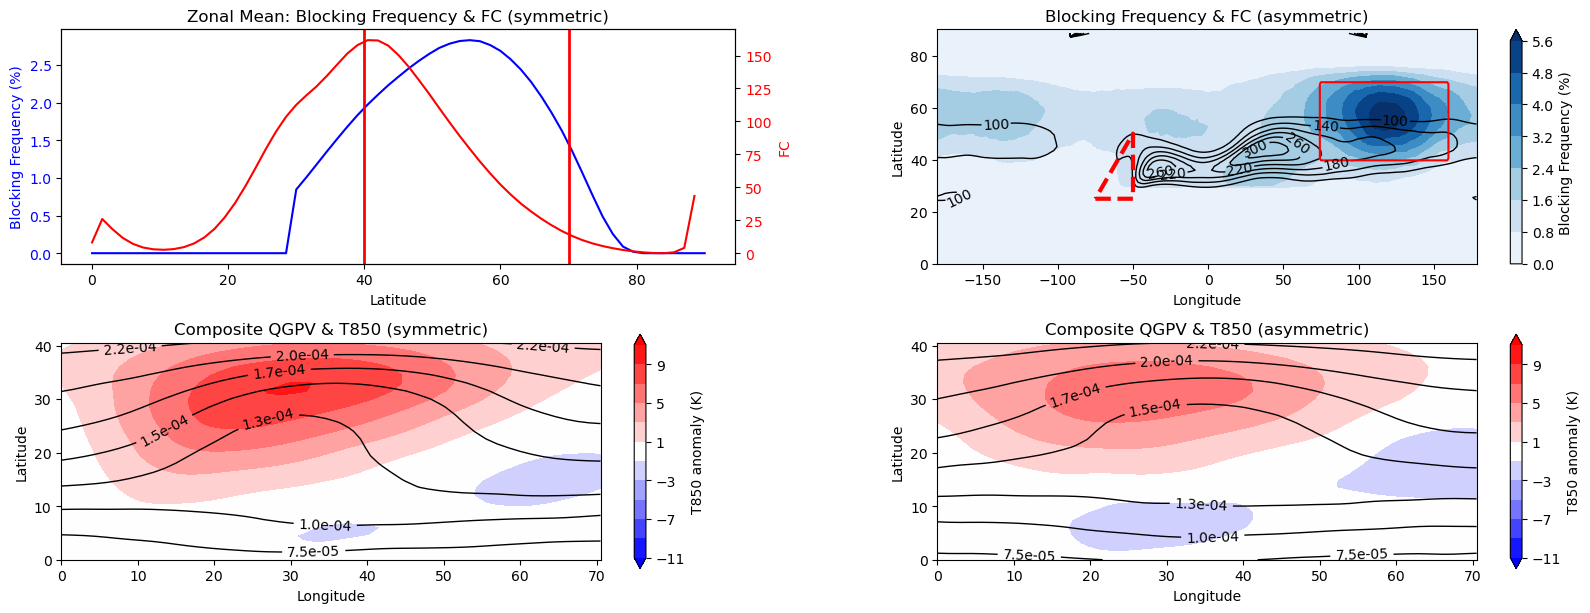

In [13]:
# Python

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

fig = plt.figure(figsize=(20, 7))
gs = gridspec.GridSpec(2, 2, figure=fig, wspace=0.3, hspace=0.3)

# First row: 1D and 2D plots (no Cartopy)
ax1 = [fig.add_subplot(gs[0, i]) for i in range(2)]

# Top left: zonal mean plot with twinx
block_freq_0 = ds_clims[0]['block_freq']
FC_0 = ds_clims[0]['FC']

lat = block_freq_0['lat']
block_freq_0_zonal = np.mean(block_freq_0, axis=-1)  # mean over longitude
FC_0_zonal = np.mean(FC_0, axis=-1)

ax1_left = ax1[0]
ax1_right = ax1_left.twinx()

p1 = ax1_left.plot(lat, block_freq_0_zonal, color='blue', label='Blocking Frequency')
ax1_left.set_ylabel('Blocking Frequency (%)', color='blue')
ax1_left.tick_params(axis='y', labelcolor='blue')

p2 = ax1_right.plot(lat, FC_0_zonal, color='red', label='FC')
ax1_right.set_ylabel('FC', color='red')
ax1_right.tick_params(axis='y', labelcolor='red')

ax1_left.set_xlabel('Latitude')
ax1_left.set_title('Zonal Mean: Blocking Frequency & FC (symmetric)')

# Add vertical red lines at 40 and 70 degrees latitude
ax1_left.axvline(x=40, color='red', linestyle='-', linewidth=2)
ax1_left.axvline(x=70, color='red', linestyle='-', linewidth=2)

# Top right: 2D fields (no Cartopy)
mask_asymmetric = define_mask(40,70,75,160)
block_freq_2 = ds_clims[2]['block_freq']
FC_2 = ds_clims[2]['FC']
FC_levels = np.arange(100, 400, 40)

cf2 = ax1[1].contourf(block_freq_2['lon'], block_freq_2['lat'], block_freq_2, extend = 'max', cmap='Blues')
cfc2 = ax1[1].contour(FC_2['lon'], FC_2['lat'], FC_2, FC_levels, colors='k', linewidths=1)
cdc3 = ax1[1].contour(block_freq_2['lon'], block_freq_2['lat'], mask_asymmetric, levels = [0.5,1.5], colors='red', alpha=1)
ax1[1].plot(lons, lats, linestyle='--',linewidth=3, color='red')
ax1[1].clabel(cfc2, fmt='%d', fontsize=10)  # Add contour labels
ax1[1].set_title('Blocking Frequency & FC (asymmetric)')
fig.colorbar(cf2, ax=ax1[1], orientation='vertical', label='Blocking Frequency (%)')
ax1[1].set_xlabel('Longitude')
ax1[1].set_ylabel('Latitude')

# composites

exp_names = ['symmetric', 'asymmetric']
t850_ano_levels = np.arange(-11,12,2)

ax2 = [fig.add_subplot(gs[1, i]) for i in range(2)]
for i in range(2):
    comp_qgpv = ds_composites[i*2]['composite_qgpv']
    comp_t850_ano = ds_composites[i*2]['composite_t850_ano']

    pcm = ax2[i].contourf(comp_t850_ano['lon'], comp_t850_ano['lat'], comp_t850_ano, t850_ano_levels, extend ='both', cmap='bwr')
    fig.colorbar(pcm, ax=ax2[i], orientation='vertical', label='T850 anomaly (K)')

    cs = ax2[i].contour(comp_qgpv['lon'], comp_qgpv['lat'], comp_qgpv, colors='k', linewidths=1)
    ax2[i].clabel(cs, fmt='%.1e', fontsize=10)  # Scientific notation, larger font

    ax2[i].set_title(f'Composite QGPV & T850 ({exp_names[i]})')
    ax2[i].set_xlabel('Longitude')
    ax2[i].set_ylabel('Latitude')
    ax2[i].set_aspect(0.7)

plt.show()